In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [9]:
SEED = 407

def add_bias(X):
    """Prepend the x0 = 1 column. Input (N, d); Output (N, d+1)."""
    return np.column_stack([np.ones(len(X)), X])

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def new_ax(xlabel, ylabel, title, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(alpha=0.3)
    return fig, ax

B.1 Gradient descent on a non-linear surface

$E(u,v) = e^u + e^{2v} + e^{uv} + u^2 - 2uv + 2v^2 - 3u - 2v$

Gradient used in the code, from B.1(a):

$\partial E/\partial u = e^u + v\,e^{uv} + 2u - 2v - 3$

$\partial E/\partial v = 2e^{2v} + u\,e^{uv} - 2u + 4v - 2$

B.1(c) Gradient descent for three learning rates

In [10]:
def E(u, v):
    return np.exp(u) + np.exp(2 * v) + np.exp(u * v) + u**2 - 2 * u * v + 2 * v**2 - 3 * u - 2 * v

def grad_E(u, v):
    dE_du = np.exp(u) + v * np.exp(u * v) + 2 * u - 2 * v - 3
    dE_dv = 2 * np.exp(2 * v) + u * np.exp(u * v) - 2 * u + 4 * v - 2
    return np.array([dE_du, dE_dv])

def gd(eta, T=50, start=(0.0, 0.0)):
    """Run T steps of p <- p - eta * grad E(p). Returns the path (T+1, 2) and E along it."""
    p = np.array(start, dtype=float)
    path, errs = [p.copy()], [E(*p)]
    for t in range(T):
        p = p - eta * grad_E(*p)
        path.append(p.copy())
        errs.append(E(*p))
    return np.array(path), np.array(errs)

etas = [0.01, 0.1, 0.25]
runs = {eta: gd(eta) for eta in etas}

Check against the hand computation in B.1(b): the first two steps with η = 0.1.

In [11]:
path, errs = runs[0.1]
check = pd.DataFrame({
    "step": [0, 1, 2],
    "u": path[:3, 0],
    "v": path[:3, 1],
    "E(u, v)": errs[:3],
})
check.round(4)

,step,u,v,"E(u, v)"
0,0,0.0000,0.00,3.0000
1,1,0.2000,0.00,2.6614
2,2,0.3379,0.02,2.4974


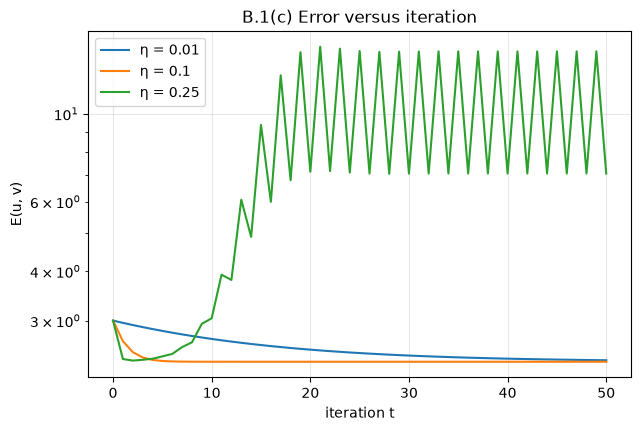

In [12]:
fig, ax = new_ax("iteration t", "E(u, v)", "B.1(c) Error versus iteration", logy=True)
for eta, (path, errs) in runs.items():
    ax.plot(errs, label=f"η = {eta}")
ax.legend(); fig.savefig("B1c_error.png", dpi=150)

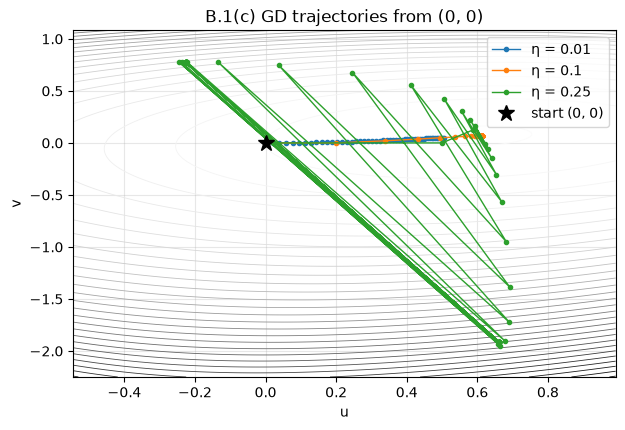

In [13]:
all_pts = np.vstack([path for path, _ in runs.values()])
pad = 0.3
u_lo, u_hi = all_pts[:, 0].min() - pad, all_pts[:, 0].max() + pad
v_lo, v_hi = all_pts[:, 1].min() - pad, all_pts[:, 1].max() + pad
U, V = np.meshgrid(np.linspace(u_lo, u_hi, 300), np.linspace(v_lo, v_hi, 300))

fig, ax = new_ax("u", "v", "B.1(c) GD trajectories from (0, 0)")
cs = ax.contour(U, V, E(U, V), levels=30, cmap="Greys", linewidths=0.6)
for eta, (path, errs) in runs.items():
    ax.plot(path[:, 0], path[:, 1], "o-", ms=3, lw=1, label=f"η = {eta}")
ax.plot(0, 0, "k*", ms=12, label="start (0, 0)")
ax.legend(); fig.savefig("B1c_paths.png", dpi=150)

B.1(d) Which η reaches the smallest E after 50 iterations?

In [14]:
summary = pd.DataFrame({
    "eta": etas,
    "u_50": [runs[e][0][-1, 0] for e in etas],
    "v_50": [runs[e][0][-1, 1] for e in etas],
    "E_50": [runs[e][1][-1] for e in etas],
    "E decreases every step": [bool(np.all(np.diff(runs[e][1]) <= 1e-12)) for e in etas],  # tolerance for float noise after convergence
    "|E_50 - E_49|": [abs(runs[e][1][-1] - runs[e][1][-2]) for e in etas],
})
print("Smallest E after 50 iterations: eta =", etas[int(summary["E_50"].argmin())])
summary.round(5)

Smallest E after 50 iterations: eta = 0.1


,eta,u_50,v_50,E_50,E decreases every step,|E_50 - E_49|
0,0.01,0.50610,0.05186,2.38170,True,0.00157
1,0.10,0.61181,0.07050,2.36082,True,0.00000
2,0.25,-0.22601,0.77350,7.06304,False,7.32272


η = 0.1 has the smallest E after 50 iterations. The largest η=0.25 jumps overa local minima again and again and is not able to reach it. The smallest η=0.01 reaches minima a lot longer and it takes more itarations for it to reach it, so η = 0.1 gets there a lot earlier, while η=0.01 is still not at 0 after 50 iterations.